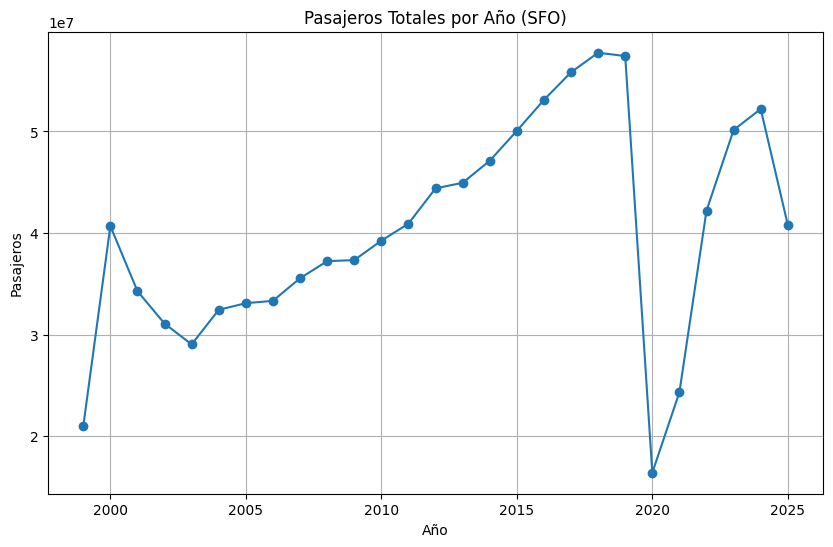

In [127]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import plotly.graph_objects as go

if df['Passenger Count'].dtype == 'O':
    df['Passenger Count'] = df['Passenger Count'].str.replace(',', '').astype(int)
#Mothly data
monthly_data = df.groupby('Activity Period')['Passenger Count'].sum().reset_index()

# Convert to datetime for proper plotting
monthly_data['Date'] = pd.to_datetime(monthly_data['Activity Period'].astype(str), format='%Y%m')
monthly_data = monthly_data.sort_values('Date')
dataset_values = monthly_data['Passenger Count'].values.reshape(-1, 1)

monthly_data["Year"] = monthly_data["Date"].dt.year

yearly_data = monthly_data.groupby('Year')["Passenger Count"].sum().reset_index()

plt.figure(figsize=(10, 6))
plt.plot(yearly_data['Year'], yearly_data['Passenger Count'], marker='o')
plt.title("Pasajeros Totales por Año (SFO)")
plt.xlabel("Año")
plt.ylabel("Pasajeros")
plt.grid(True)
plt.show()

In [128]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Dropout
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error

In [129]:
# fix random seed for reproducibility
tf.random.set_seed(7)

In [130]:
train_size = int(len(yearly_data) * 0.8)

train = yearly_data[:train_size]
test = yearly_data[train_size:]

In [131]:
scaler = MinMaxScaler(feature_range=(0,1))

train_scaled = scaler.fit_transform(train)
test_scaled = scaler.transform(test)

def create_dataset(dataset, lookback=1):
    X_data, Y_data = [], []
    for i in range(len(dataset) - lookback - 1):
        a = dataset[i:i+lookback, 0]
        X_data.append(a)
        Y_data.append(dataset[i + lookback, 0])
    return np.array(X_data), np.array(Y_data)

In [132]:
look_back = 3

trainX, trainY = create_dataset(train_scaled, look_back)
testX, testY = create_dataset(test_scaled, look_back)


In [133]:
trainX = trainX.reshape(trainX.shape[0], trainX.shape[1], 1)
testX  = testX.reshape(testX.shape[0],  testX.shape[1],  1)

In [134]:
model = Sequential()

model.add(LSTM(32, input_shape=(look_back, 1)))
model.add(Dropout(0.05))
model.add(Dense(1))

model.compile(loss='mean_squared_error', optimizer='adam')


/opt/anaconda3/envs/tf_lstm/lib/python3.11/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning:

Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.



In [135]:
model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_4 (LSTM)                   │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,385 (17.13 KB)

 Trainable params: 4,385 (17.13 KB)

 Non-trainable params: 0 (0.00 B)

In [136]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True
)

history = model.fit(
    trainX, trainY,
    epochs=300,
    batch_size=1,
    verbose=2,
    validation_data=(testX, testY),
    callbacks=[early_stop]

)

Epoch 1/300
17/17 - 1s - 56ms/step - loss: 0.3732 - val_loss: 1.2243
Epoch 2/300
17/17 - 0s - 10ms/step - loss: 0.2314 - val_loss: 0.8060
Epoch 3/300
17/17 - 0s - 10ms/step - loss: 0.1322 - val_loss: 0.4419
Epoch 4/300
17/17 - 0s - 10ms/step - loss: 0.0579 - val_loss: 0.1772
Epoch 5/300
17/17 - 0s - 10ms/step - loss: 0.0185 - val_loss: 0.0671
Epoch 6/300
17/17 - 0s - 11ms/step - loss: 0.0112 - val_loss: 0.0503
Epoch 7/300
17/17 - 0s - 13ms/step - loss: 0.0091 - val_loss: 0.0534
Epoch 8/300
17/17 - 0s - 11ms/step - loss: 0.0097 - val_loss: 0.0415
Epoch 9/300
17/17 - 0s - 10ms/step - loss: 0.0151 - val_loss: 0.0242
Epoch 10/300
17/17 - 0s - 10ms/step - loss: 0.0063 - val_loss: 0.0242
Epoch 11/300
17/17 - 0s - 10ms/step - loss: 0.0068 - val_loss: 0.0120
Epoch 12/300
17/17 - 0s - 11ms/step - loss: 0.0060 - val_loss: 0.0071
Epoch 13/300
17/17 - 0s - 12ms/step - loss: 0.0048 - val_loss: 0.0124
Epoch 14/300
17/17 - 0s - 11ms/step - loss: 0.0034 - val_loss: 0.0082
Epoch 15/300
17/17 - 0s - 11m

In [137]:
import plotly.graph_objects as go

# Crear figura
fig_loss = go.Figure()

# 1. Train Loss
fig_loss.add_trace(go.Scatter(
    y=history.history['loss'],
    mode='lines',
    name='Train Loss',
    line=dict(color='#FF3344', width=3)
))

# 2. Validation/Test Loss
fig_loss.add_trace(go.Scatter(
    y=history.history['val_loss'],
    mode='lines',
    name='Test Loss',
    line=dict(color='#00CC96', width=3)
))

# Configuración del diseño
fig_loss.update_layout(
    title='Curva de Aprendizaje: Training vs Test Loss',
    xaxis_title='Epoch',
    yaxis_title='Loss (MSE)',
    template='plotly_white',
    legend=dict(x=1, y=1), # Leyenda arriba a la derecha
    width=900,
    height=500
)

fig_loss.show()

In [139]:
trainPredict = model.predict(trainX)
testPredict = model.predict(testX)

trainY_inv = scaler.inverse_transform(trainY.reshape(-1,1))
testY_inv  = scaler.inverse_transform(testY.reshape(-1,1))

trainPredict_inv = scaler.inverse_transform(trainPredict)
testPredict_inv  = scaler.inverse_transform(testPredict)

train_rmse = np.sqrt(mean_squared_error(trainY_inv, trainPredict_inv))
test_rmse  = np.sqrt(mean_squared_error(testY_inv,  testPredict_inv))

print("Train RMSE:", train_rmse)
print("Test RMSE: ", test_rmse)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step


ValueError: non-broadcastable output operand with shape (17,1) doesn't match the broadcast shape (17,2)

In [140]:
import numpy as np
import plotly.graph_objects as go

# array vacío para graficar
trainPredictPlot = np.empty_like(yearly_data, dtype=float)
trainPredictPlot[:] = np.nan
trainPredictPlot[look_back:len(yearly_data)+look_back, 0] = trainPredict_inv[:,0]

testPredictPlot = np.empty_like(yearly_data, dtype=float)
testPredictPlot[:] = np.nan
test_start = train_size + look_back
testPredictPlot[test_start:test_start+len(testPredict_inv), 0] = testPredict_inv[:,0]

# gráfico
fig = go.Figure()

# 1. Actual Data (Datos Reales)
fig.add_trace(go.Scatter(
    y=yearly_data[:,0],
    mode='lines',
    name='Actual Data',  # Traducido
    line=dict(color="#32C7F9")
))

# 2. Train Prediction
fig.add_trace(go.Scatter(
    y=trainPredictPlot[:,0],
    mode='lines',
    name='Train Predictions', # Traducido
    line=dict(color="#FD4A59", width=4)
))

# 3. Test Prediction
fig.add_trace(go.Scatter(
    y=testPredictPlot[:,0],
    mode='lines',
    name='Test Predictions', # Traducido
    line=dict(color='#00CC96', width=4)
))

# Configuración del diseño
fig.update_layout(
    title='Airline Passenger Traffic Forecast (LSTM)', # Traducido
    xaxis_title='Time (Months)', # Traducido
    yaxis_title='Passenger Count', # Traducido
    template='plotly_white',
    legend=dict(x=0, y=1, traceorder="normal"),
    width=1000, 
    height=500
)

fig.show()

ValueError: could not broadcast input array from shape (8,) into shape (24,)

In [141]:
# 1. Escalar todo el dataset si no lo tenías
data_scaled = scaler.transform(yearly_data)

# 2. Obtener la última ventana
last_window = data_scaled[-look_back:]

# 3. Reshape para el LSTM
last_window = last_window.reshape(1, look_back, 1)

# 4. Predicción
next_scaled = model.predict(last_window)

# 5. Desescalar
next_value = scaler.inverse_transform(next_scaled)
print("Predicción del próximo mes:", next_value[0][0])

ValueError: cannot reshape array of size 6 into shape (1,3,1)